<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/fabiobento/lab-cont-2026-2-privado/blob/main/modulo2_plano_s/labs/lab_revisao_resposta_subamortecida.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

# Lab de Revisão — A Resposta Subamortecida e suas Fórmulas

**Módulo 02 · Revisão de abertura (§2.1.1) · Laboratório de Controle Automático (Ifes Guarapari)**

> **Material de apresentação em aula.** O notebook vem com todas as células executadas, para ser projetado e
> discutido. Cada parte tem um **✏️ Pause** (os alunos arriscam uma previsão *antes* de rodar a célula) e uma
> **Leitura do resultado** (a resposta). Os três itens de **Sua vez** vêm com resolução completa ao final.

Neste laboratório vamos:
1. Recuperar a **geometria do polo** subamortecido ($\sigma$, $\omega_d$, $\omega_n$, $\beta=\arccos\zeta$);
2. Conferir por simulação as **quatro fórmulas** — $M_p$, $t_p$, $t_r$, $t_s$ — no exemplo da teoria;
3. Ver **de onde elas vêm** (a forma fechada de $y(t)$) e por que três são exatas;
4. Testar a **aproximação do $t_s$** ao longo de toda a faixa de $\zeta$ (ela merece mais cuidado do que parece);
5. Usar a **fórmula inversa** $\zeta(M_p)$ — e evitar a armadilha de colocar o $M_p$ em porcentagem;
6. Descobrir **quando as fórmulas deixam de valer** (zeros e polos extras) — o que motiva o resto do Módulo 02.

**Teoria de apoio:** `teoria_modulo2.md`, §2.1.1. Retoma o Lab 04 (Módulo 01).

In [1]:
# %% IMPORTS (rode esta célula primeiro)
!pip install --quiet control==0.10.2
import control as ct
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True

def step(G, t):
    t, y = ct.step_response(G, t)
    return np.asarray(t), np.asarray(y)

def medir(T, t=None):
    """Mede Mp(%), tp, tr(0-100%) e ts(±5%) da resposta ao degrau de T."""
    if t is None: t = np.linspace(0, 50, 50000)
    t, y = step(T, t)
    yss = y[-1]
    Mp = 100*(y.max()-yss)/yss; tp = t[np.argmax(y)]
    tr = t[np.argmax(y >= yss)]
    fora = np.where(np.abs(y-yss) > 0.05*abs(yss))[0]
    ts = t[fora[-1]] if len(fora) else 0.0
    return dict(Mp=Mp, tp=tp, tr=tr, ts=ts, yss=yss)

def padrao(zeta, wn):
    """FT padrão de 2ª ordem: wn² / (s² + 2ζωn s + wn²)."""
    return ct.tf([wn**2], [1, 2*zeta*wn, wn**2])

def formulas(zeta, wn):
    """As quatro fórmulas da §2.1.1 (Mp em %)."""
    sigma = zeta*wn; wd = wn*np.sqrt(1 - zeta**2); beta = np.arccos(zeta)
    return dict(Mp=100*np.exp(-zeta*np.pi/np.sqrt(1 - zeta**2)), tp=np.pi/wd, tr=(np.pi - beta)/wd, ts=3/sigma)

print('python-control', ct.__version__)

python-control 0.10.2


## Parte 1 — A geometria do polo

Os polos de $G(s)=\dfrac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2}$ são
$$s=-\zeta\omega_n\pm j\,\omega_n\sqrt{1-\zeta^2}=-\sigma\pm j\,\omega_d,$$
e formam um **triângulo retângulo** no plano-s: catetos $\sigma$ (horizontal) e $\omega_d$ (vertical), hipotenusa
$\omega_n=\sqrt{\sigma^2+\omega_d^2}$ (a distância do polo à origem), e o ângulo $\beta$ entre a hipotenusa e o eixo
real negativo satisfaz $\cos\beta=\sigma/\omega_n=\zeta$, isto é, **$\beta=\arccos\zeta$**.

**✏️ Pause:** para $\zeta=0{,}45$ e $\omega_n=2$ rad/s, onde fica o polo? Antes de rodar: quanto valem $\sigma$, $\omega_d$ e $\beta$?

polo (python-control)  : -0.9000+1.7861j
-σ + jωd (fórmulas)    : -0.9000 + 1.7861j   (σ = 0.9, ωd = 1.7861)
β = arccos ζ = 1.1040 rad = 63.26°   |   |polo| = 2.0000 = ωn   |   σ²+ωd² = 4.0000 = ωn²


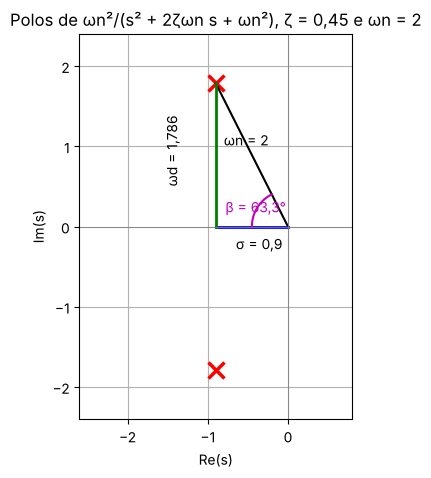

In [2]:
zeta, wn = 0.45, 2.0
T = padrao(zeta, wn)
sigma = zeta*wn; wd = wn*np.sqrt(1 - zeta**2); beta = np.arccos(zeta)
polo = ct.poles(T)[np.argmax(ct.poles(T).imag)]
print(f'polo (python-control)  : {polo:.4f}')
print(f'-σ + jωd (fórmulas)    : {-sigma:.4f} + {wd:.4f}j   (σ = {sigma}, ωd = {wd:.4f})')
print(f'β = arccos ζ = {beta:.4f} rad = {np.degrees(beta):.2f}°   |   |polo| = {abs(polo):.4f} = ωn   |   σ²+ωd² = {sigma**2 + wd**2:.4f} = ωn²')

fig, ax = plt.subplots(figsize=(6.5, 5))
for sgn in (+1, -1):
    ax.plot(-sigma, sgn*wd, 'rx', ms=12, mew=2.5)
ax.plot([0, -sigma], [0, wd], 'k-', lw=1.5); ax.plot([0, -sigma], [0, 0], 'b-', lw=2); ax.plot([-sigma, -sigma], [0, wd], 'g-', lw=2)
ax.annotate('ωn = 2', (-sigma/2 - 0.35, wd/2 + 0.12)); ax.annotate('σ = 0,9', (-sigma/2 - 0.2, -0.28)); ax.annotate('ωd = 1,786', (-sigma - 0.65, wd/2 - 0.35), rotation=90)
th = np.linspace(np.pi - beta, np.pi, 40); ax.plot(0.45*np.cos(th), 0.45*np.sin(th), 'm-'); ax.annotate('β = 63,3°', (-0.78, 0.18), color='m')
ax.axhline(0, color='gray', lw=0.6); ax.axvline(0, color='gray', lw=0.6)
ax.set_xlim(-2.6, 0.8); ax.set_ylim(-2.4, 2.4); ax.set_aspect('equal')
ax.set_xlabel('Re(s)'); ax.set_ylabel('Im(s)'); ax.set_title('Polos de ωn²/(s² + 2ζωn s + ωn²), ζ = 0,45 e ωn = 2');

**Leitura do resultado.** $\sigma=\zeta\omega_n=0{,}9$, $\omega_d=\omega_n\sqrt{1-\zeta^2}=1{,}786$ e $\beta=\arccos0{,}45=63{,}26°$; o polo está em
$-0{,}9+1{,}786j$ e a verificação $\sigma^2+\omega_d^2=4=\omega_n^2$ fecha o triângulo. Este desenho é o **vocabulário do Módulo 02**:
a partir daqui, cada requisito de desempenho será uma região do plano-s descrita por $\beta$ (overshoot), $\omega_d$ (tempo de pico)
e $\sigma$ (tempo de acomodação).

## Parte 2 — As quatro fórmulas no exemplo da teoria

$$M_p=e^{-\zeta\pi/\sqrt{1-\zeta^2}},\qquad t_p=\frac{\pi}{\omega_d},\qquad t_r=\frac{\pi-\arccos\zeta}{\omega_d},\qquad t_s(5\%)\approx\frac{3}{\sigma}.$$

Exemplo da §2.1.1: $\zeta=0{,}45$, $\omega_n=2$ rad/s ⇒ $M_p=20{,}5\%$, $t_p=1{,}76$ s, $t_r=1{,}14$ s, $t_s=3{,}33$ s.

**✏️ Pause:** a simulação vai concordar com as quatro fórmulas? Alguma deve diferir — qual, e em que sentido?

                 fórmula   simulação
Mp (%)            20.535      20.533
tp (s)             1.759       1.759
tr (s)             1.141       1.141
ts 5% (s)          3.333       2.623


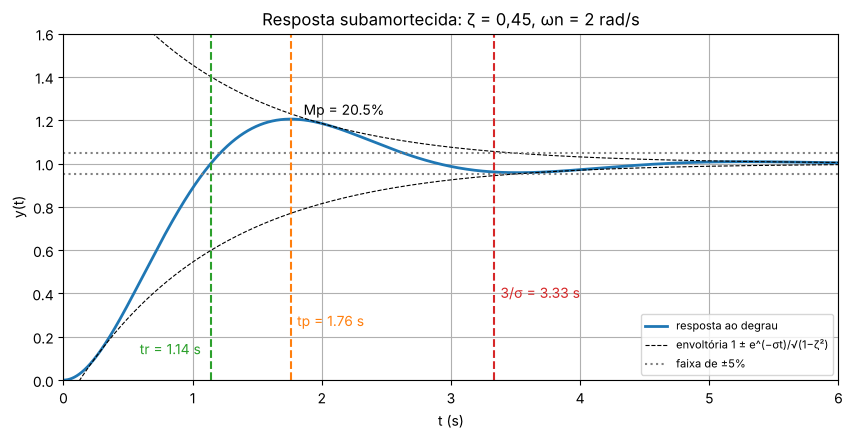

In [3]:
T = padrao(0.45, 2.0)
t = np.linspace(0, 12, 120001)
f = formulas(0.45, 2.0); m = medir(T, t)
print(f'{"":14s}{"fórmula":>10s}{"simulação":>12s}')
for k, nome in [('Mp', 'Mp (%)'), ('tp', 'tp (s)'), ('tr', 'tr (s)'), ('ts', 'ts 5% (s)')]:
    print(f'{nome:14s}{f[k]:10.3f}{m[k]:12.3f}')

tt, y = step(T, t)
sigma, wd = 0.9, 2*np.sqrt(1 - 0.45**2)
env = np.exp(-sigma*tt)/np.sqrt(1 - 0.45**2)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tt, y, lw=2, label='resposta ao degrau')
ax.plot(tt, 1 + env, 'k--', lw=0.8, label='envoltória 1 ± e^(−σt)/√(1−ζ²)'); ax.plot(tt, 1 - env, 'k--', lw=0.8)
ax.axhline(1.05, color='gray', ls=':'); ax.axhline(0.95, color='gray', ls=':', label='faixa de ±5%')
ax.axvline(f['tp'], color='C1', ls='--'); ax.annotate(f"tp = {f['tp']:.2f} s", (f['tp'] + 0.05, 0.25), color='C1')
ax.axvline(f['tr'], color='C2', ls='--'); ax.annotate(f"tr = {f['tr']:.2f} s", (f['tr'] - 0.55, 0.12), color='C2')
ax.axvline(f['ts'], color='C3', ls='--'); ax.annotate(f"3/σ = {f['ts']:.2f} s", (f['ts'] + 0.05, 0.38), color='C3')
ax.annotate(f"Mp = {f['Mp']:.1f}%", (f['tp'] + 0.1, y.max() + 0.02))
ax.set_xlim(0, 6); ax.set_ylim(0, 1.6); ax.set_xlabel('t (s)'); ax.set_ylabel('y(t)'); ax.legend(fontsize=8, loc='lower right')
ax.set_title('Resposta subamortecida: ζ = 0,45, ωn = 2 rad/s');

**Leitura do resultado.** As três primeiras fórmulas concordam com a simulação até a 3ª casa decimal
($20{,}53\%$, $1{,}759$ s e $1{,}141$ s): são **exatas**. A quarta, não: $3/\sigma=3{,}33$ s, mas a saída *entra e não sai mais* da faixa
de $\pm5\%$ já em $2{,}62$ s — a fórmula usa a **envoltória exponencial** (curvas tracejadas), que decai mais devagar do que a
oscilação real. Neste exemplo a aproximação é **pessimista** (nos deixa com folga); a Parte 4 mostra que isso nem sempre é verdade.

## Parte 3 — De onde vêm as fórmulas

A resposta ao degrau unitário do sistema padrão subamortecido tem forma fechada
$$y(t)=1-\frac{e^{-\sigma t}}{\sqrt{1-\zeta^2}}\,\sin\bigl(\omega_d t+\beta\bigr),\qquad \beta=\arccos\zeta .$$

- **Tempo de pico.** $\dot y(t)=\dfrac{\omega_n}{\sqrt{1-\zeta^2}}\,e^{-\sigma t}\sin(\omega_d t)$ (use $\sigma\sin(\omega_dt+\beta)-\omega_d\cos(\omega_dt+\beta)=-\omega_n\sin(\omega_d t)$).
  Os extremos estão em $\sin(\omega_dt)=0$; o primeiro é $\omega_d t_p=\pi\Rightarrow\boxed{t_p=\pi/\omega_d}$.
- **Overshoot.** $y(t_p)=1-\dfrac{e^{-\sigma\pi/\omega_d}}{\sqrt{1-\zeta^2}}\sin(\pi+\beta)=1+e^{-\sigma\pi/\omega_d}$, pois $\sin\beta=\sqrt{1-\zeta^2}$.
  Logo $M_p=e^{-\sigma\pi/\omega_d}=\boxed{e^{-\zeta\pi/\sqrt{1-\zeta^2}}}$.
- **Tempo de subida (0–100%).** $y=1$ pela primeira vez quando $\sin(\omega_dt+\beta)=0$, isto é, $\omega_dt_r+\beta=\pi\Rightarrow\boxed{t_r=(\pi-\beta)/\omega_d}$.
- **Tempo de acomodação.** O que *sobra* de $y$ é limitado pela envoltória: $|y-1|\le e^{-\sigma t}/\sqrt{1-\zeta^2}$. Impondo $e^{-\sigma t}=0{,}05$
  (e ignorando o fator $1/\sqrt{1-\zeta^2}$, que vale ≈ 1,1 para $\zeta=0{,}45$) resulta $t_s\approx\ln20/\sigma\approx3/\sigma$ — **uma estimativa, não uma dedução exata**.

Conferimos a forma fechada contra o simulador:

In [4]:
zeta, wn = 0.45, 2.0
sigma, wd, beta = zeta*wn, wn*np.sqrt(1 - zeta**2), np.arccos(zeta)
t = np.linspace(0, 10, 100001)
_, y_sim = step(padrao(zeta, wn), t)
y_fech = 1 - np.exp(-sigma*t)/np.sqrt(1 - zeta**2)*np.sin(wd*t + beta)
print(f'máx |y_simulador − y_forma_fechada| = {np.abs(y_sim - y_fech).max():.1e}')

# derivada: dy/dt = ωn/√(1−ζ²) · e^(−σt) · sin(ωd t)   (zera em t = kπ/ωd)
dy_num = np.gradient(y_fech, t)
dy_ana = wn/np.sqrt(1 - zeta**2)*np.exp(-sigma*t)*np.sin(wd*t)
print(f'máx |dy/dt numérica − analítica| = {np.abs(dy_num - dy_ana).max():.1e}')

k = np.arange(1, 5)
print('\nextremos de y(t) em t = kπ/ωd:  ', np.round(k*np.pi/wd, 3), 's')
print('valores de y nesses instantes:   ', np.round(1 - np.exp(-sigma*k*np.pi/wd)/np.sqrt(1 - zeta**2)*np.sin(k*np.pi + beta), 4))
print('  1º = 1 + Mp ; 2º = 1 − Mp² ; 3º = 1 + Mp³ ... com Mp =', round(np.exp(-sigma*np.pi/wd), 4))

# tempo de subida: y(tr) = 1
tr = (np.pi - beta)/wd
print(f'\ny(tr) com tr = (π−β)/ωd = {tr:.4f} s:  {1 - np.exp(-sigma*tr)/np.sqrt(1 - zeta**2)*np.sin(wd*tr + beta):.6f}')

# a "faixa" de ts: quando a envoltória cruza 5%
env_t = np.log(20/np.sqrt(1 - zeta**2)) / sigma
print(f'envoltória = 5% em t = {env_t:.3f} s (com o fator 1/√(1−ζ²))  |  ln20/σ = {np.log(20)/sigma:.3f} s  |  3/σ = {3/sigma:.3f} s')

máx |y_simulador − y_forma_fechada| = 3.3e-13
máx |dy/dt numérica − analítica| = 2.0e-04

extremos de y(t) em t = kπ/ωd:   [1.759 3.518 5.277 7.036] s
valores de y nesses instantes:    [1.2053 0.9578 1.0087 0.9982]
  1º = 1 + Mp ; 2º = 1 − Mp² ; 3º = 1 + Mp³ ... com Mp = 0.2053

y(tr) com tr = (π−β)/ωd = 1.1408 s:  1.000000
envoltória = 5% em t = 3.454 s (com o fator 1/√(1−ζ²))  |  ln20/σ = 3.329 s  |  3/σ = 3.333 s


**Leitura do resultado.** A forma fechada reproduz o simulador com diferença da ordem de $10^{-13}$, e os extremos de $y$ caem exatamente em
$t=k\pi/\omega_d$ ($1{,}759$; $3{,}518$; ...). Os valores sucessivos formam uma sequência notável: $1+M_p$, $1-M_p^2$, $1+M_p^3,\dots$ — cada
oscilação é $M_p$ vezes a anterior (razão de decaimento constante). O $t_r$ da fórmula leva $y$ a $1{,}000000$ exatamente. Já o $t_s$ é outra história:
a envoltória cruza $5\%$ em $3{,}45$ s (com o fator $1/\sqrt{1-\zeta^2}$) ou em $3{,}33$ s ($3/\sigma$) — nenhum dos dois é o $t_s$ real de $2{,}62$ s,
porque a *oscilação* só encosta na envoltória nos picos. Daí a diferença.

## Parte 4 — O $t_s \approx 3/\sigma$ ao longo de toda a faixa de $\zeta$

A teoria diz que $3/\sigma$ é uma "aproximação pessimista". Vamos testar, varrendo $\zeta$ de $0{,}05$ a $0{,}95$ (com $\omega_n=1$; o
resultado só escala com $\omega_n$, a *razão* $t_s^{sim}\!/(3/\sigma)$ não muda).

**✏️ Pause:** a razão $t_s^{sim}/(3/\sigma)$ será sempre menor que $1$? Como você espera que ela se comporte quando $\zeta\to1$?

ζ ∈ [0.05, 0.60]: razão entre 0.77 e 1.05
ζ ∈ [0.05, 0.80]: razão entre 0.68 e 1.09
ζ ∈ [0.80, 0.95]: razão entre 0.90 e 1.38
  ζ = 0.45: ts_sim = 5.25, 3/σ = 6.67, razão = 0.79
  ζ = 0.5: ts_sim = 5.29, 3/σ = 6.00, razão = 0.88
  ζ = 0.7: ts_sim = 2.90, 3/σ = 4.29, razão = 0.68
  ζ = 0.9: ts_sim = 4.01, 3/σ = 3.33, razão = 1.20


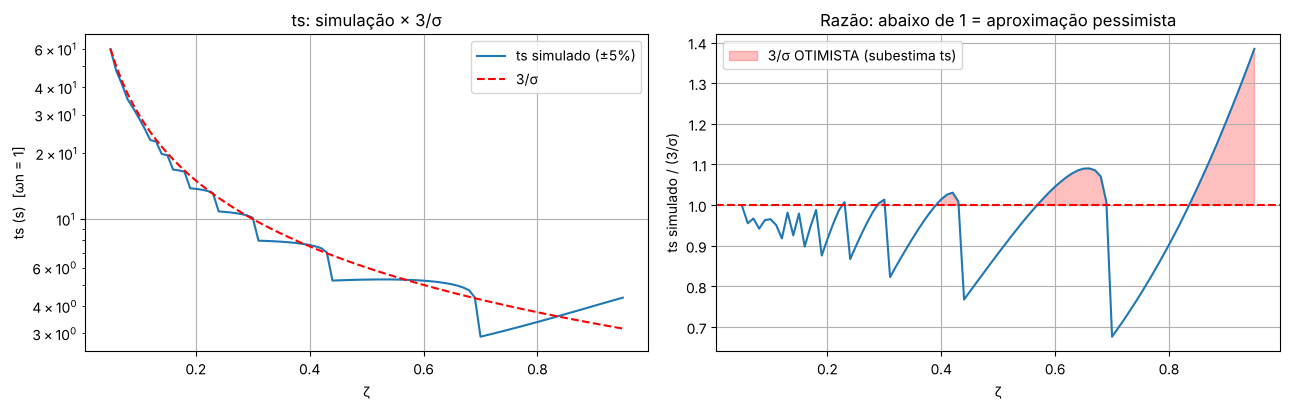

In [5]:
zs = np.arange(0.05, 0.951, 0.01)
ts_sim, ts_apr = [], []
for z in zs:
    m = medir(padrao(z, 1.0), np.linspace(0, 400, 200001))
    ts_sim.append(m['ts']); ts_apr.append(3/z)
ts_sim, ts_apr = np.array(ts_sim), np.array(ts_apr)
razao = ts_sim/ts_apr

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(zs, ts_sim, label='ts simulado (±5%)'); axs[0].plot(zs, ts_apr, 'r--', label='3/σ'); axs[0].set_yscale('log')
axs[0].set_xlabel('ζ'); axs[0].set_ylabel('ts (s)  [ωn = 1]'); axs[0].legend(); axs[0].set_title('ts: simulação × 3/σ')
axs[1].plot(zs, razao, lw=1.5); axs[1].axhline(1, color='r', ls='--'); axs[1].set_xlabel('ζ'); axs[1].set_ylabel('ts simulado / (3/σ)')
axs[1].fill_between(zs, 1, razao, where=razao > 1, color='r', alpha=0.25, label='3/σ OTIMISTA (subestima ts)')
axs[1].legend(); axs[1].set_title('Razão: abaixo de 1 = aproximação pessimista')
plt.tight_layout()

for lo, hi in [(0.05, 0.6), (0.05, 0.8), (0.8, 0.95)]:
    k = (zs >= lo - 1e-9) & (zs <= hi + 1e-9)
    print(f'ζ ∈ [{lo:.2f}, {hi:.2f}]: razão entre {razao[k].min():.2f} e {razao[k].max():.2f}')
for z in (0.45, 0.5, 0.7, 0.9):
    i = np.argmin(abs(zs - z)); print(f'  ζ = {z}: ts_sim = {ts_sim[i]:.2f}, 3/σ = {ts_apr[i]:.2f}, razão = {razao[i]:.2f}')

**Leitura do resultado (e resposta ao ✏️ Pause).** A razão **não** é sempre menor que $1$:

- Para $\zeta\le0{,}6$ ela fica entre $0{,}77$ e $1{,}05$: **o $3/\sigma$ acerta com erro de poucos por cento**, para mais ou para menos;
- Entre $\zeta\approx0{,}57$ e $0{,}69$ a razão passa de $1$ (até $1{,}09$): a aproximação é **levemente otimista** — nesta faixa a oscilação ainda
  encosta nos $5\%$ no 2º pico e o $t_s$ simulado "salta" para além de $3/\sigma$;
- Para $\zeta\gtrsim0{,}85$ o $3/\sigma$ **subestima** o $t_s$ por até $38\%$ (em $\zeta=0{,}95$: $4{,}37$ s contra $3{,}16$ s): com amortecimento
  alto o polo "lento" domina a cauda e o modelo de envoltória deixa de valer.

O gráfico à esquerda também mostra a natureza *em degraus* do $t_s$ medido: ele é o último instante fora da faixa, e quando um pico passa de dentro para
fora dos $5\%$ o valor salta. **Conclusão de projeto:** $t_s\approx3/\sigma$ é uma boa regra para $0{,}2\lesssim\zeta\lesssim0{,}8$ (os casos de
interesse neste curso, $\zeta\approx0{,}5$), mas sempre se **confirma por simulação** — exatamente o que faremos em todos os labs do módulo.

## Parte 5 — A fórmula inversa: do overshoot ao amortecimento

Do $M_p=e^{-\zeta\pi/\sqrt{1-\zeta^2}}$: $\ln M_p=-\dfrac{\zeta\pi}{\sqrt{1-\zeta^2}}\Rightarrow\ln^2M_p\,(1-\zeta^2)=\zeta^2\pi^2$, logo
$$\zeta=\sqrt{\frac{\ln^2M_p}{\pi^2+\ln^2M_p}}\qquad(M_p\ \text{em fração, não em porcentagem!})$$

**✏️ Pause:** se alguém colocar $M_p=10$ (porcentagem) em vez de $0{,}10$, o resultado muda? E se colocar $M_p=20$ em vez de $0{,}20$?

In [6]:
def zeta_de_Mp(Mp_frac):
    L = np.log(Mp_frac)
    return np.sqrt(L**2/(np.pi**2 + L**2))

print(f'{"Mp (%)":>8s}{"ζ":>9s}{"β = arccos ζ":>16s}')
for Mp_pct in [5, 10, 15, 16.3, 20, 25]:
    z = zeta_de_Mp(Mp_pct/100)
    print(f'{Mp_pct:8.1f}{z:9.4f}{np.degrees(np.arccos(z)):14.2f}°')

print('\nA ARMADILHA — usar a porcentagem no lugar da fração:')
for Mp_pct in [10, 20, 16.3]:
    print(f'  Mp = {Mp_pct:>4}%: correto ζ = {zeta_de_Mp(Mp_pct/100):.4f} | errado (Mp={Mp_pct}) ζ = {zeta_de_Mp(Mp_pct):.4f}')

# ida e volta: ζ → Mp → ζ
z0 = 0.45
Mp0 = np.exp(-z0*np.pi/np.sqrt(1 - z0**2)); print(f'\nida e volta: ζ = {z0} → Mp = {Mp0:.4f} → ζ = {zeta_de_Mp(Mp0):.4f}')

  Mp (%)        ζ    β = arccos ζ
     5.0   0.6901         46.36°
    10.0   0.5912         53.76°
    15.0   0.5169         58.87°
    16.3   0.5000         60.00°
    20.0   0.4559         62.87°
    25.0   0.4037         66.19°

A ARMADILHA — usar a porcentagem no lugar da fração:
  Mp =   10%: correto ζ = 0.5912 | errado (Mp=10) ζ = 0.5912
  Mp =   20%: correto ζ = 0.4559 | errado (Mp=20) ζ = 0.6901
  Mp = 16.3%: correto ζ = 0.5000 | errado (Mp=16.3) ζ = 0.6642

ida e volta: ζ = 0.45 → Mp = 0.2053 → ζ = 0.4500


**Leitura do resultado (e resposta ao ✏️ Pause).**

| $M_p$ | $\zeta$ | $\beta=\arccos\zeta$ |
|---|---|---|
| $5\%$ | $0{,}690$ | $46{,}4°$ |
| $10\%$ | $0{,}591$ | $53{,}8°$ |
| $15\%$ | $0{,}517$ | $58{,}9°$ |
| $16{,}3\%$ | $0{,}500$ | $60{,}0°$ |
| $20\%$ | $0{,}456$ | $62{,}9°$ |
| $25\%$ | $0{,}404$ | $66{,}2°$ |

(O "$16{,}3\%$" que aparece por todo o curso é só o $M_p$ de $\zeta=0{,}5$.)

**A armadilha é traiçoeira:** para $M_p=10\%$ o erro **não aparece**, pois $\ln10=-\ln0{,}1$ e a fórmula só usa $\ln^2M_p$ — dá $\zeta=0{,}591$ nos dois casos!
Mas para $M_p=20$ (em vez de $0{,}20$) o resultado é $\zeta=0{,}690$, em vez de $0{,}456$ — um polo bem diferente. Cuidado ao validar a fórmula só com o exemplo de $10\%$.

## Parte 6 — Quando as fórmulas deixam de valer

As quatro fórmulas valem **exatamente** para $\dfrac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2}$: 2ª ordem, **sem zeros**, ganho DC $=1$.
O que acontece com um **zero** ou com um **3º polo**? Fixamos o par dominante em $\zeta=0{,}45$, $\omega_n=2$ ($\sigma=0{,}9$) e variamos:

- zero em $-a$: $T(s)=\dfrac{(s+a)}{a}\cdot\dfrac{4}{s^2+1{,}8s+4}$ (mantém o ganho DC);
- polo extra em $-p$: $T(s)=\dfrac{p}{s+p}\cdot\dfrac{4}{s^2+1{,}8s+4}$.

**✏️ Pause:** um zero *perto* da origem aumenta ou diminui o overshoot? E um polo extra *perto* da origem?

ZERO em −a:


  a =   100: Mp =   20.5%  tp = 1.75 s  tr = 1.13 s  ts = 2.61 s


  a =     3: Mp =   26.9%  tp = 1.36 s  tr = 0.75 s  ts = 3.36 s


  a =     1: Mp =   78.8%  tp = 0.91 s  tr = 0.29 s  ts = 3.47 s


  a =   0.5: Mp =  185.4%  tp = 0.76 s  tr = 0.14 s  ts = 4.78 s
POLO EXTRA em −p:


  p =    50: Mp =   20.5%  tp = 1.78 s  tr = 1.16 s  ts = 2.64 s


  p =    10: Mp =   20.1%  tp = 1.87 s  tr = 1.25 s  ts = 2.73 s


  p =     5: Mp =   18.7%  tp = 1.99 s  tr = 1.37 s  ts = 2.83 s


  p =     2: Mp =   10.9%  tp = 2.37 s  tr = 1.78 s  ts = 3.01 s


  p =     1: Mp =    0.0%  tp = 9.86 s  tr = 9.52 s  ts = 2.50 s


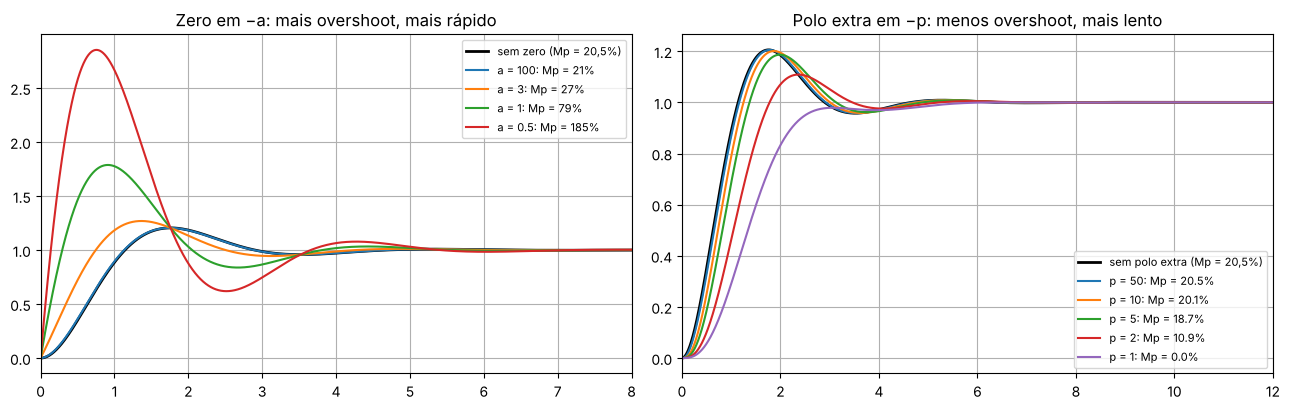

In [7]:
t = np.linspace(0, 20, 20001)
base = padrao(0.45, 2.0)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(*step(base, t), 'k-', lw=2, label='sem zero (Mp = 20,5%)')
print('ZERO em −a:')
for a in [100, 3, 1, 0.5]:
    T = ct.tf([4/a, 4], [1, 1.8, 4]); m = medir(T, t)
    axs[0].plot(*step(T, t), label=f'a = {a}: Mp = {m["Mp"]:.0f}%'); print(f'  a = {a:>5}: Mp = {m["Mp"]:6.1f}%  tp = {m["tp"]:.2f} s  tr = {m["tr"]:.2f} s  ts = {m["ts"]:.2f} s')
axs[0].set_xlim(0, 8); axs[0].set_title('Zero em −a: mais overshoot, mais rápido'); axs[0].legend(fontsize=8)
axs[1].plot(*step(base, t), 'k-', lw=2, label='sem polo extra (Mp = 20,5%)')
print('POLO EXTRA em −p:')
for p in [50, 10, 5, 2, 1]:
    T = ct.tf([4*p], np.polymul([1, 1.8, 4], [1, p])); m = medir(T, t)
    axs[1].plot(*step(T, t), label=f'p = {p}: Mp = {m["Mp"]:.1f}%'); print(f'  p = {p:>5}: Mp = {m["Mp"]:6.1f}%  tp = {m["tp"]:.2f} s  tr = {m["tr"]:.2f} s  ts = {m["ts"]:.2f} s')
axs[1].set_xlim(0, 12); axs[1].set_title('Polo extra em −p: menos overshoot, mais lento'); axs[1].legend(fontsize=8)
plt.tight_layout()

**Leitura do resultado (e resposta ao ✏️ Pause).**

- **Zero:** quanto *mais perto* da origem (menor $a$), *maior* o overshoot e menor o tempo de subida: $20{,}5\%$ ($a=100$, sem efeito) $\to26{,}9\%$ ($a=3$) $\to78{,}8\%$ ($a=1$) $\to185\%$ ($a=0{,}5$).
  O zero "empurra" a resposta para cima: $y_1=y+\dot y/a$.
- **Polo extra:** quanto *mais perto* da origem, *menos* overshoot e *mais lento* o sistema: $20{,}5\%\to18{,}7\%$ ($p=5$) $\to10{,}9\%$ ($p=2$) $\to0\%$ ($p=1$, praticamente superamortecido: o $t_r$ vai a $9{,}5$ s).
- Só quando o zero ou o 3º polo está **bem longe** do par ($a$ ou $p\gtrsim5\sigma$, aqui $\approx5$) as fórmulas da §2.1.1 continuam servindo como aproximação — é a **regra dos 5×** que
  veremos na §2.1.7 e no Lab 05. Moral desta revisão: *as fórmulas são exatas para o modelo padrão; para o resto, usamos o modelo padrão como aproximação — e simulamos para conferir.*

## Sua vez

1. **Do polo às fórmulas.** Um sistema de 2ª ordem padrão tem polos em $-3\pm4j$. Obtenha $\omega_n$, $\zeta$, $\sigma$, $\omega_d$, $\beta$ e, com as fórmulas, $M_p$, $t_p$, $t_r$ e $t_s$. Confira por simulação.
2. **Dos requisitos ao polo.** Projete o **polo desejado** $\square_d$ (e a FT padrão) para $M_p=15\%$ e $t_p=0{,}5$ s. Qual é o $t_s$ estimado? Confira por simulação.
3. **Escalamento.** Dobre o $\omega_n$ do exemplo da teoria ($\zeta=0{,}45$, $\omega_n:2\to4$ rad/s). O que acontece com $M_p$, $t_p$, $t_r$, $t_s$ e com a posição do polo? Generalize: o que muda e o que não muda quando só o $\omega_n$ cresce?

---
# Respostas

## Resposta 1 — Do polo às fórmulas ($-3\pm4j$)

$\omega_n=|{-3}+4j|=\sqrt{9+16}=5$ rad/s; $\sigma=3$; $\omega_d=4$; $\zeta=\sigma/\omega_n=0{,}6$; $\beta=\arccos0{,}6=53{,}13°$ (o triângulo $3$–$4$–$5$).
Então
$$M_p=e^{-0{,}6\pi/0{,}8}=e^{-0{,}75\pi}=9{,}48\%,\quad t_p=\frac{\pi}{4}=0{,}785\ \text{s},\quad t_r=\frac{\pi-0{,}9273}{4}=0{,}554\ \text{s},\quad t_s\approx\frac33=1{,}00\ \text{s}.$$

In [8]:
p = -3 + 4j
wn1 = abs(p); sigma1 = -p.real; wd1 = p.imag; zeta1 = sigma1/wn1; beta1 = np.arccos(zeta1)
print(f'ωn = {wn1}, σ = {sigma1}, ωd = {wd1}, ζ = {zeta1}, β = {np.degrees(beta1):.2f}°')
f1 = formulas(zeta1, wn1); m1 = medir(padrao(zeta1, wn1), np.linspace(0, 6, 60001))
print(f'{"":10s}{"fórmula":>10s}{"simulação":>12s}')
for k, nome in [('Mp', 'Mp (%)'), ('tp', 'tp (s)'), ('tr', 'tr (s)'), ('ts', 'ts (s)')]:
    print(f'{nome:10s}{f1[k]:10.3f}{m1[k]:12.3f}')
print('denominador:', padrao(zeta1, wn1).den[0][0], '→ s² + 6s + 25')

ωn = 5.0, σ = 3.0, ωd = 4.0, ζ = 0.6, β = 53.13°


             fórmula   simulação
Mp (%)         9.478       9.478
tp (s)         0.785       0.785
tr (s)         0.554       0.554
ts (s)         1.000       1.046
denominador: [ 1.  6. 25.] → s² + 6s + 25


**Confirmado.** $M_p=9{,}478\%$, $t_p=0{,}785$ s e $t_r=0{,}554$ s batem com a simulação até a 3ª casa. O $t_s$ estimado ($1{,}00$ s) fica um pouco abaixo do simulado
($1{,}05$ s): com $\zeta=0{,}6$ estamos exatamente na zona em que a aproximação $3/\sigma$ é levemente otimista (Parte 4). A FT é
$T(s)=\dfrac{25}{s^2+6s+25}$.

## Resposta 2 — Dos requisitos ao polo ($M_p=15\%$, $t_p=0{,}5$ s)

1. $M_p=0{,}15\Rightarrow\zeta=\sqrt{\dfrac{\ln^2 0{,}15}{\pi^2+\ln^20{,}15}}=0{,}517$ ($\beta=58{,}87°$);
2. $t_p=\pi/\omega_d=0{,}5\Rightarrow\omega_d=2\pi=6{,}283$ rad/s;
3. $\omega_n=\omega_d/\sqrt{1-\zeta^2}=7{,}340$ rad/s e $\sigma=\zeta\omega_n=3{,}794$;
4. $\square_d=-3{,}794+6{,}283j$ e $T(s)=\dfrac{53{,}87}{s^2+7{,}588s+53{,}87}$;
5. $t_s\approx3/\sigma=0{,}79$ s e $t_r=(\pi-\beta)/\omega_d=0{,}336$ s.

(O polo mora no cruzamento da reta $\omega_d=2\pi$ com o raio de ângulo $\beta=58{,}87°$ — a interseção de **duas regiões** do plano-s, tema da §2.1.6.)

In [9]:
zeta2 = zeta_de_Mp(0.15); wd2 = np.pi/0.5
wn2 = wd2/np.sqrt(1 - zeta2**2); sigma2 = zeta2*wn2
print(f'ζ = {zeta2:.4f}  β = {np.degrees(np.arccos(zeta2)):.2f}°  ωd = {wd2:.3f}  ωn = {wn2:.3f}  σ = {sigma2:.3f}')
print(f'□d = {-sigma2:.3f} + {wd2:.3f}j   |   denominador: s² + {2*zeta2*wn2:.3f}s + {wn2**2:.2f}')
T2 = padrao(zeta2, wn2); m2 = medir(T2, np.linspace(0, 4, 40001)); f2 = formulas(zeta2, wn2)
print(f'Mp: fórmula {f2["Mp"]:.2f}% | sim {m2["Mp"]:.2f}%   tp: {f2["tp"]:.3f} | {m2["tp"]:.3f}   tr: {f2["tr"]:.3f} | {m2["tr"]:.3f}   ts: 3/σ = {f2["ts"]:.3f} | sim {m2["ts"]:.3f}')
print('polos conferidos:', np.round(ct.poles(T2), 3))

ζ = 0.5169  β = 58.87°  ωd = 6.283  ωn = 7.340  σ = 3.794
□d = -3.794 + 6.283j   |   denominador: s² + 7.588s + 53.87


Mp: fórmula 15.00% | sim 15.00%   tp: 0.500 | 0.500   tr: 0.336 | 0.337   ts: 3/σ = 0.791 | sim 0.721
polos conferidos: [-3.794+6.283j -3.794-6.283j]


**Confirmado.** A simulação dá $M_p=15{,}00\%$ e $t_p=0{,}500$ s — os dois requisitos atendidos *com igualdade* (esse é o ponto do projeto: o polo está na fronteira das duas regiões).
O $t_r=0{,}336$ s bate com a fórmula, e o $t_s$ simulado ($0{,}72$ s) fica abaixo da estimativa $3/\sigma=0{,}79$ s.

## Resposta 3 — Escalamento: $\omega_n:2\to4$ com $\zeta$ fixo

O polo se escreve $s=\omega_n\bigl(-\zeta\pm j\sqrt{1-\zeta^2}\bigr)$: dobrar $\omega_n$ **multiplica o polo por 2**, ao longo do mesmo raio (mesmo $\beta$). Os efeitos:

- $M_p$ e $\beta$ dependem só de $\zeta$ ⇒ **não mudam** ($20{,}5\%$);
- $t_p,\ t_r,\ t_s$ são proporcionais a $1/\omega_n$ ⇒ **caem pela metade**;
- $\sigma$ e $\omega_d$ dobram.

Ou seja: $\zeta$ comanda a **forma** da resposta e $\omega_n$ comanda a **escala de tempo** — o sistema com $\omega_n=4$ é o do $\omega_n=2$ visto em câmera rápida (a curva $y(t)$ de um é $y(2t)$ do outro).

ωn = 2.0: polo = -0.900+1.786j | Mp = 20.53%  tp = 1.759  tr = 1.141  ts = 2.623   (3/σ = 3.333)


ωn = 4.0: polo = -1.800+3.572j | Mp = 20.53%  tp = 0.880  tr = 0.571  ts = 1.312   (3/σ = 1.667)
razões ωn=4 / ωn=2:  tp 0.500   tr 0.500   ts 0.500


máx |y_ωn=4(t) − y_ωn=2(2t)| = 0.0e+00


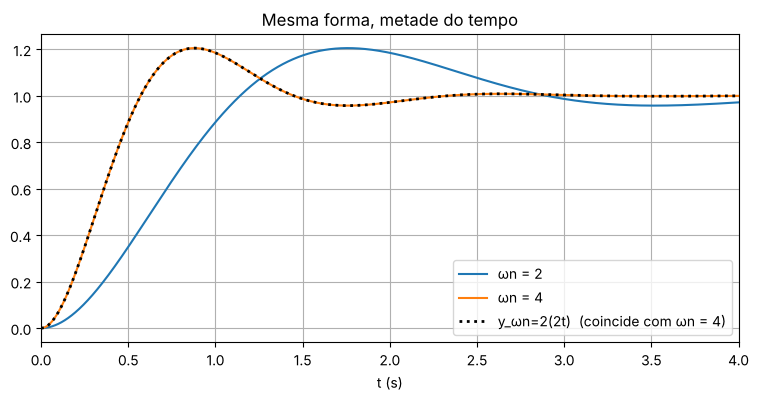

In [10]:
t = np.linspace(0, 12, 120001)
res = {}
for wn_ in (2.0, 4.0):
    T = padrao(0.45, wn_); m = medir(T, t); f = formulas(0.45, wn_); res[wn_] = (T, m)
    pol = ct.poles(T)[np.argmax(ct.poles(T).imag)]
    print(f'ωn = {wn_}: polo = {pol:.3f} | Mp = {m["Mp"]:.2f}%  tp = {m["tp"]:.3f}  tr = {m["tr"]:.3f}  ts = {m["ts"]:.3f}   (3/σ = {f["ts"]:.3f})')
print(f'razões ωn=4 / ωn=2:  tp {res[4.0][1]["tp"]/res[2.0][1]["tp"]:.3f}   tr {res[4.0][1]["tr"]/res[2.0][1]["tr"]:.3f}   ts {res[4.0][1]["ts"]/res[2.0][1]["ts"]:.3f}')

tt, y2 = step(res[2.0][0], t); _, y4 = step(res[4.0][0], t)
_, y4b = step(res[2.0][0], 2*t)                           # y_{ωn=2}(2t) — deve coincidir com y_{ωn=4}(t)
print(f'máx |y_ωn=4(t) − y_ωn=2(2t)| = {np.abs(y4 - y4b).max():.1e}')
plt.plot(tt, y2, label='ωn = 2'); plt.plot(tt, y4, label='ωn = 4'); plt.plot(tt, y4b, 'k:', lw=2, label='y_ωn=2(2t)  (coincide com ωn = 4)')
plt.xlim(0, 4); plt.xlabel('t (s)'); plt.legend(); plt.title('Mesma forma, metade do tempo');

**Confirmado.** Com $\omega_n=4$: polo em $-1{,}8+3{,}572j$, $M_p=20{,}53\%$ (igual), $t_p=0{,}880$ s, $t_r=0{,}571$ s e $t_s=1{,}31$ s — **exatamente a metade** dos
tempos do caso $\omega_n=2$ (razões $0{,}500$). A curva do sistema rápido coincide com a do lento comprimida por 2 no tempo (diferença numericamente nula). Este escalamento é a razão
pela qual, no Módulo 02, uma região do plano-s pode ser descrita por **ângulo** ($M_p$) e **distâncias** ($t_p$, $t_s$, $t_r$) separadamente.